# Household Electricity Consumption Prediction

## Data Cleaning

This notebook cleans the dataset before machine learning.

The main tasks are:
- Detect missing values
- Handle missing values
- Detect duplicate records
- Check invalid values
- Prepare a clean dataset

In [5]:
import pandas as pd

In [6]:
df=pd.read_csv(r"C:\Users\Shehan\OneDrive\Desktop\PROJECT_\data\household_power_consumption.csv")
df.head()

,Month,Province,District,Household_Type,Household_Size,House_Area_m2,Bedrooms,AC_Units,Fans,Refrigerators,...,Other_High_Power_Appliances,Avg_Daily_AC_Hours,Avg_Daily_Fan_Hours,Avg_Daily_TV_Hours,Avg_Daily_Cooking_Hours,Solar_PV,Solar_Capacity_kW,Avg_Temperature_C,Previous_Month_kWh,Target_Monthly_kWh
0,January,Eastern,Ampara,Single_Family,4,69.1,1,1.0,4,1,...,3,5.1,4.7,3.5,3.3,No,0.0,30.3,369.7,350.8
1,January,Eastern,Ampara,Apartment,6,54.1,2,0.0,7,1,...,0,0.0,NaN,6.3,3.0,No,0.0,30.3,290.9,281.8
2,January,North Central,Anuradhapura,Single_Family,2,196.9,5,0.0,3,1,...,1,0.0,10.7,4.1,3.9,No,NaN,25.4,241.6,277.9
3,January,North Central,Anuradhapura,Single_Family,4,122.8,3,0.0,4,2,...,3,0.0,9.2,5.7,3.7,No,0.0,27.4,270.7,286.7
4,January,Uva,Badulla,Single_Family,5,93.9,2,0.0,5,1,...,2,0.0,4.7,2.7,1.4,No,0.0,29.6,307.3,303.0


In [7]:
missing_percentage=df.isnull().mean()*100
missing_percentage[missing_percentage>0]

House_Area_m2          3.0
AC_Units               2.0
Avg_Daily_AC_Hours     4.0
Avg_Daily_Fan_Hours    3.0
Solar_Capacity_kW      2.0
Avg_Temperature_C      3.0
Previous_Month_kWh     5.0
dtype: float64

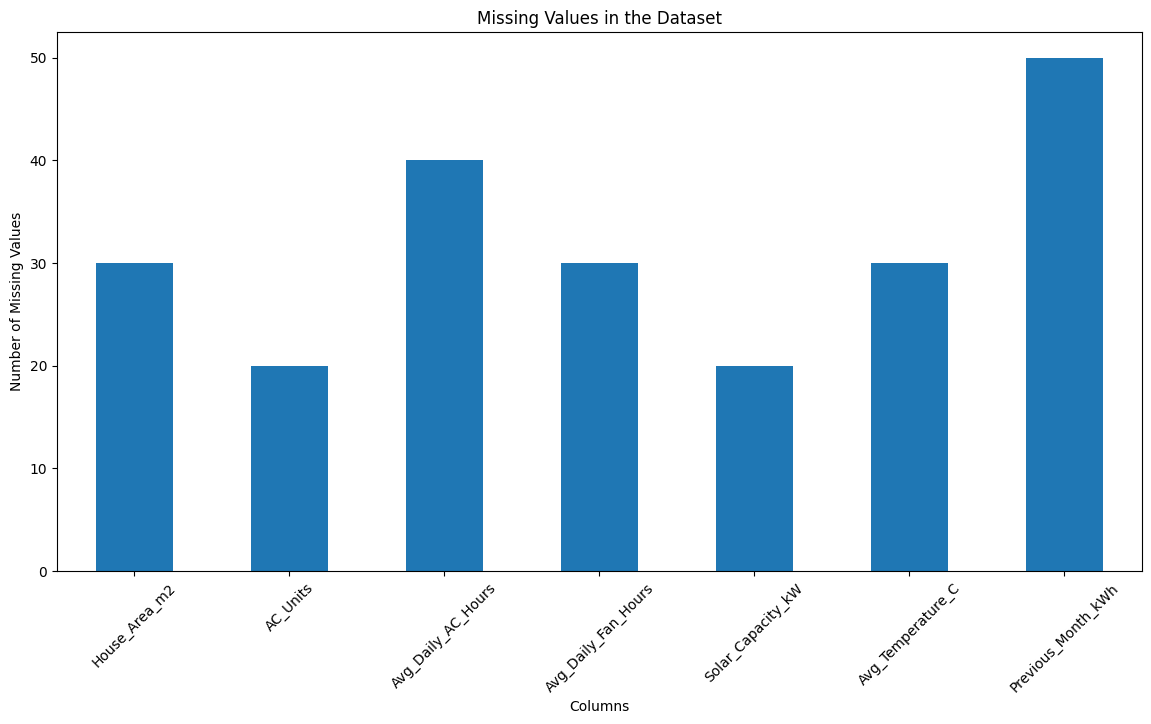

In [8]:
import matplotlib.pyplot as plt
missing=df.isnull().sum()
missing=missing[missing>0]
plt.figure(figsize=(14,7))
missing.plot(kind="bar")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.title("Missing Values in the Dataset")

plt.xticks(rotation=45)

plt.show()




In [9]:
numeric_column=["House_Area_m2","AC_Units","Avg_Daily_AC_Hours","Avg_Daily_Fan_Hours","Solar_Capacity_kW","Avg_Temperature_C","Previous_Month_kWh"]

In [10]:
for column in numeric_column:
    df[column] = df[column].fillna(df[column].median())

In [11]:
df.isnull().sum()

Month                          0
Province                       0
District                       0
Household_Type                 0
Household_Size                 0
House_Area_m2                  0
Bedrooms                       0
AC_Units                       0
Fans                           0
Refrigerators                  0
TVs                            0
Washing_Machines               0
Water_Heaters                  0
Computers                      0
Other_High_Power_Appliances    0
Avg_Daily_AC_Hours             0
Avg_Daily_Fan_Hours            0
Avg_Daily_TV_Hours             0
Avg_Daily_Cooking_Hours        0
Solar_PV                       0
Solar_Capacity_kW              0
Avg_Temperature_C              0
Previous_Month_kWh             0
Target_Monthly_kWh             0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.dtypes

Month                              str
Province                           str
District                           str
Household_Type                     str
Household_Size                   int64
House_Area_m2                  float64
Bedrooms                         int64
AC_Units                       float64
Fans                             int64
Refrigerators                    int64
TVs                              int64
Washing_Machines                 int64
Water_Heaters                    int64
Computers                        int64
Other_High_Power_Appliances      int64
Avg_Daily_AC_Hours             float64
Avg_Daily_Fan_Hours            float64
Avg_Daily_TV_Hours             float64
Avg_Daily_Cooking_Hours        float64
Solar_PV                           str
Solar_Capacity_kW              float64
Avg_Temperature_C              float64
Previous_Month_kWh             float64
Target_Monthly_kWh             float64
dtype: object

In [14]:
df[numeric_column].min()

House_Area_m2          40.0
AC_Units                0.0
Avg_Daily_AC_Hours      0.0
Avg_Daily_Fan_Hours     4.0
Solar_Capacity_kW       0.0
Avg_Temperature_C      25.0
Previous_Month_kWh     69.1
dtype: float64

In [15]:
df["Target_Monthly_kWh"].describe()

count    1000.000000
mean      336.968300
std        87.105358
min       100.700000
25%       274.250000
50%       330.050000
75%       393.275000
max       600.200000
Name: Target_Monthly_kWh, dtype: float64

In [16]:
(df["Target_Monthly_kWh"] < 0).sum()

np.int64(0)

In [17]:
df.to_csv(r"C:\Users\Shehan\OneDrive\Desktop\PROJECT_\data\cleaned_data.csv",index=False)

In [19]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Rows: 1000
Columns: 24
Missing values: 0
Duplicate rows: 0
